# 05: Checking the Rankings a Different Way

Notebook 03 estimated how fast each driver is with a **Bayesian hierarchical model**: one number per
driver and per constructor fitted at the same time, a range around each rather than a single figure,
and a driver with only a handful of sessions pulled toward the grid average instead of trusted.

The answer looked sensible. Verstappen at the top, the drivers everyone remembers as slow at the
bottom.

**Looking sensible proves very little.** Almost any model fitted to F1 lap times will rank Verstappen
highly, because Verstappen is fast. A ranking that agrees with what fans already believe has not been
tested, it has only avoided being obviously wrong.

**The real test is whether a second method, built on different ideas, produces the same order.** If it
does, the ranking comes from the lap times rather than from the choices inside one model. If it does
not, the disagreement shows where to be careful.

### The second method: chess ratings

Chess has F1's problem: thousands of players, most pairs never meet, and somebody still has to rank
them all. Elo works through matches in date order and adjusts after each one, the winner up and the
loser down, by more when the result was a surprise.

**Teammates are F1's version of a chess match.** Two drivers in the same car, prepared by the same
team, in the same session. Whoever set the quicker lap won a fair fight. Chain those across eight
seasons, with drivers moving between teams, and the grid links up.

Two caveats. The comparison is **Q1 only**, following notebook 01, so these win rates will not match
the season-long qualifying head-to-heads published elsewhere. And "identical machinery" is an
approximation: upgrade parts often arrive on one car first.

### What this can and cannot check

**It checks the driver half of the answer only.** Comparing teammates cancels the car out completely,
so this method can rank drivers and can say nothing about which constructor built the quickest car.
That is the price of that unusually clean comparison, and why the hierarchical model was needed.

**The two methods are not independent, because both start from the same lap times.** What differs is
everything above them, and that is what the comparison later has to be measured against.

## Building the head-to-head record

**What counts as a match here?** One qualifying session, one team, its two drivers, and whoever set
the quicker lap. That gives one row per teammate pair per session.

Laps more than 7% slower than the session's fastest are excluded, the same rule notebook 01 applied.
This is F1's own 107% rule: a driver that far off the pace was almost certainly dealing with a spin,
damage or a red flag rather than trying for a fast lap, so losing to a teammate on such a lap should
not be counted as a defeat.

In [64]:
!pip install -q arviz

import glob
import os

import numpy as np
import pandas as pd
import arviz as az
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

pd.set_option('display.max_columns', None)

available = glob.glob('/kaggle/input/**/*', recursive=True)
print('files visible to this notebook:')
for path in available:
    if os.path.isfile(path):
        print(' ', path)

csv_matches = [p for p in available if p.endswith('model_data.csv')]
nc_matches = [p for p in available if p.endswith('model_sqrt.nc')]

if not csv_matches or not nc_matches:
    raise FileNotFoundError(
        'Attach the dataset holding model_data.csv and model_sqrt.nc '
        '(Notebook sidebar -> Input -> Add Input), then re-run.'
    )

model_data = pd.read_csv(csv_matches[0])
idata = az.from_netcdf(nc_matches[0])

print()
print('driver-sessions:', len(model_data))
print('seasons:', model_data['season'].min(), '-', model_data['season'].max())
model_data.head()

files visible to this notebook:
  /kaggle/input/datasets/mikandr/model-sqrt/model_sqrt.nc
  /kaggle/input/datasets/mikandr/model-data/model_data.csv
  /kaggle/input/datasets/mikandr/q1-pace/q1_pace.csv

driver-sessions: 3008
seasons: 2018 - 2025


,season,gp,team,drv,best_lap,n_valid_laps,gap_to_fastest,rain_fraction,within_107,team_season,sqrt_gap
0,2018,Abu Dhabi Grand Prix,Ferrari,RAI,97.010,3,0.242831,0.0,True,Ferrari 2018,0.492779
1,2018,Abu Dhabi Grand Prix,Ferrari,VET,96.775,3,0.000000,0.0,True,Ferrari 2018,0.000000
2,2018,Abu Dhabi Grand Prix,Haas F1 Team,GRO,97.575,1,0.826660,0.0,True,Haas F1 Team 2018,0.909208
3,2018,Abu Dhabi Grand Prix,Haas F1 Team,MAG,97.934,2,1.197623,0.0,True,Haas F1 Team 2018,1.094360
4,2018,Abu Dhabi Grand Prix,McLaren,ALO,97.890,3,1.152157,0.0,True,McLaren 2018,1.073386


### Where the calendar order comes from

**Elo needs the races in the order they happened.** Each update starts from the ratings as they stood
at that moment, so a result in March changes what the method expects of the same two drivers in May.

**One problem in the pairing.** A duel is awarded to whichever teammate set the quicker lap, and three
of the 1,475 have no quicker lap: Raikkonen and Vettel at Brazil 2018, Alonso and Ocon at Spain 2021,
and Hamilton and Russell at Japan 2023 each recorded identical gaps. The sort that picks the winner
has no tie-break, so those three go to whichever driver happens to sort first. Flipping them moves six
drivers by one Elo place. That is small but not nothing: three results in this record were decided by
row order rather than by pace.

The order is part of the method, not a presentation detail. `model_data` records the season and
the Grand Prix name but not the round, and sorting by name would
process Abu Dhabi, the finale, first. The calendar therefore comes from the Ergast/F1DB mirror already
used in notebook 04, which carries a `round` column.

In [65]:
import io
import zipfile
import requests

archive = requests.get(
    'https://raw.githubusercontent.com/TracingInsights/RaceData/main/data.zip', timeout=60
)
with zipfile.ZipFile(io.BytesIO(archive.content)) as z:
    calendar = pd.read_csv(z.open('races.csv'))

calendar = (calendar[calendar['year'].between(2018, 2025)]
            [['year', 'round', 'name']]
            .rename(columns={'year': 'season', 'name': 'gp'}))

unmatched = (set(map(tuple, model_data[['season', 'gp']].drop_duplicates().values))
             - set(map(tuple, calendar[['season', 'gp']].values)))
print('sessions with no calendar entry:', len(unmatched))
print(sorted(unmatched)[:5] if unmatched else '')

dated = model_data.merge(calendar, on=['season', 'gp'], how='left')
print('rows missing a round number:', dated['round'].isna().sum())
print()
print('first five races of 2018, in calendar order:')
print(dated[dated['season'] == 2018].sort_values('round')['gp'].drop_duplicates().head())

sessions with no calendar entry: 0

rows missing a round number: 0

first five races of 2018, in calendar order:
66        Bahrain Grand Prix
135       Chinese Grand Prix
42     Azerbaijan Grand Prix
278       Spanish Grand Prix
228        Monaco Grand Prix
Name: gp, dtype: object


In [66]:
def build_head_to_head(df):
    """One row per teammate pair per session: same car, so the faster lap wins."""
    pairs, unpaired = [], 0
    for (season, rnd, team), entry in df.groupby(['season', 'round', 'team']):
        if len(entry) != 2:
            unpaired += len(entry)
            continue
        faster, slower = entry.sort_values('gap_to_fastest').itertuples(index=False)
        pairs.append({
            'season': season,
            'round': rnd,
            'team': team,
            'winner': faster.drv,
            'loser': slower.drv,
            'margin': slower.gap_to_fastest - faster.gap_to_fastest,
        })
    print(f'{unpaired} driver-sessions had no teammate to pair with and are dropped')
    return pd.DataFrame(pairs).sort_values(['season', 'round']).reset_index(drop=True)


head_to_head = build_head_to_head(dated)

print('head-to-head results:', len(head_to_head))
print('drivers involved:', len(set(head_to_head['winner']) | set(head_to_head['loser'])))
print()
print('first races of 2018, now in calendar order:')
print(head_to_head.head(8).to_string(index=False))

58 driver-sessions had no teammate to pair with and are dropped
head-to-head results: 1475
drivers involved: 43

first races of 2018, now in calendar order:
 season  round            team winner loser   margin
   2018      2     Force India    PER   OCO 0.134267
   2018      2    Haas F1 Team    MAG   GRO 1.047284
   2018      2         McLaren    VAN   ALO 0.057064
   2018      2 Red Bull Racing    VER   RIC 0.199163
   2018      2         Renault    SAI   HUL 0.410634
   2018      2          Sauber    ERI   LEC 0.399445
   2018      2      Toro Rosso    GAS   HAR 0.325598
   2018      2        Williams    SIR   STR 0.022378


In [67]:
appearances = pd.concat([head_to_head['winner'], head_to_head['loser']]).value_counts()
print('head-to-heads per driver:')
print(appearances.describe().round(1))
print()
print('fewest:')
print(appearances.tail(6))

head-to-heads per driver:
count     43.0
mean      68.6
std       52.7
min        1.0
25%       21.0
50%       59.0
75%      120.5
max      153.0
Name: count, dtype: float64

fewest:
KUB    15
HAR    14
DEV    10
DOO     6
FIT     2
AIT     1
Name: count, dtype: int64


### Some drivers barely appear

**The number of teammate duels per driver runs from 1 to 153, with a median of 59.** Aitken has one,
Fittipaldi two, Doohan six. All three appeared in only a handful of qualifying sessions across the
whole 2018 to 2025 period, so there is almost nothing to rate them on.

**Both methods handle that by pulling such drivers toward the middle, and neither says so out loud.**
The hierarchical model does it deliberately: a thin record borrows from the grid average and gets a
wide range around it, the model admitting it does not know. Elo arrives at the same place by accident.
A rating can only move `k` points per duel, so a driver with one result cannot be more than 32 points
from where everyone starts, however that result went.

**The difference is what the two say about their own uncertainty.** The hierarchical model reports a
range. Elo reports a number that looks like everyone else's, and a reader has no way to tell whether
it rests on 1 duel or 150. Where the two disagree for these drivers, believe the hierarchical model,
not because it is centred differently but because it is honest about how little it has to go on. That
is why the comparison later is run again on only the drivers with long records.

In [68]:
present = dated.groupby('season')['round'].nunique()
scheduled = calendar.groupby('season')['round'].nunique()

coverage = pd.DataFrame({'in_data': present, 'on_calendar': scheduled})
coverage['missing'] = coverage['on_calendar'] - coverage['in_data']
print(coverage)
print()
print(f'total sessions missing: {coverage["missing"].sum()} of {coverage["on_calendar"].sum()}')

        in_data  on_calendar  missing
season                               
2018         18           21        3
2019         15           21        6
2020         17           17        0
2021         22           22        0
2022         22           22        0
2023         22           22        0
2024         16           24        8
2025         24           24        0

total sessions missing: 17 of 173


### Most missing races are inherited, and three are not explained

**Why does the 2018 season start at round 2?** The Australian Grand Prix, that year's opener, is not in
the data. Notebook 01 dropped sessions whose source files did not label which laps belonged to Q1, and
those gaps carry straight through.

17 of 173 sessions are absent. Fourteen are the 2019 and 2024 rounds notebook 01 flagged. The other
three are 2018 rounds it never flagged: **Australia, Canada and France**, which notebook 06 identifies
as sessions carrying usable Q3 laps and no usable Q1 laps at all. Since this notebook uses the Q1
table, those three drop out here and the 2018 season starts at round 2.

A missing round does not break Elo, which works through whatever results exist in whatever order they
happened, so an absent race costs information rather than causing an error. Worth stating all the same:
the ratings below rest on a slightly thinner record than a full calendar would give.

## How the rating update works

Every driver starts on 1500. Then, for each teammate duel in turn:

1. **Predict.** Turn the gap between the two ratings into a win probability. A driver 100 points ahead
   should usually be quicker; one 400 points ahead should almost always be.
2. **Compare.** Look at who actually set the better lap.
3. **Adjust.** Move both ratings toward what happened, by an amount proportional to how surprising it
   was. A clear favourite winning barely moves anything; an underdog winning moves both a long way.

**How large "adjust" should be is the one number the method leaves open, the k-factor.** Too small and
ratings never move far enough to reflect real differences; too large and they chase noise. The next
section picks a value by testing rather than by convention.

## Choosing the constants

**How much should one qualifying session move a rating?** The k-factor could be set to 32, the value
chess has used for decades. But a chess player competes dozens of times a year against a constantly
changing field, while an F1 driver faces the same teammate for a whole season. There is no reason to
assume a number tuned for one situation carries over to the other.

So it is chosen by measuring which value best predicts results the method has not been shown.

**The test respects the calendar.** Ratings are built by walking through the races in date order, and
every prediction for the 2024 and 2025 seasons is recorded *before* that race is allowed to update
anything. No prediction ever uses a result from the future. This is the same discipline as the
chronological split in notebook 04.

**Predictions are scored with log-loss rather than accuracy.** Accuracy only asks whether the
predicted winner won, so it treats a 51% call and a 99% call as the same thing. Log-loss grades the
confidence as well as the call: it rewards being confident and right, and punishes being confident
and wrong.

In [69]:
INITIAL_RATING = 1500


def run_elo(pairs, k, evaluate_from=None):
    """Walk results in order. Predictions for the held-out period are made before updating."""
    ratings = {}
    held_out = []

    for row in pairs.itertuples(index=False):
        winner_rating = ratings.get(row.winner, INITIAL_RATING)
        loser_rating = ratings.get(row.loser, INITIAL_RATING)

        expected = 1 / (1 + 10 ** ((loser_rating - winner_rating) / 400))

        if evaluate_from is not None and row.season >= evaluate_from:
            held_out.append(expected)

        surprise = 1 - expected
        ratings[row.winner] = winner_rating + k * surprise
        ratings[row.loser] = loser_rating - k * surprise

    return ratings, np.array(held_out)


scores = []
for k in [4, 8, 12, 16, 24, 32, 48, 64]:
    _, predicted = run_elo(head_to_head, k, evaluate_from=2024)
    scores.append({
        'k': k,
        'log_loss': -np.mean(np.log(np.clip(predicted, 1e-9, 1))),
        'accuracy': np.mean(predicted > 0.5),
        'held_out_results': len(predicted),
    })

k_search = pd.DataFrame(scores).set_index('k')
print(k_search.round(4))
print()
best_k = k_search['log_loss'].idxmin()
print(f'best k by log-loss: {best_k}')

    log_loss  accuracy  held_out_results
k                                       
4     0.6305    0.6864               389
8     0.6128    0.6838               389
12    0.6051    0.6710               389
16    0.6011    0.6658               389
24    0.5978    0.6684               389
32    0.5976    0.6735               389
48    0.6017    0.6607               389
64    0.6088    0.6684               389

best k by log-loss: 32


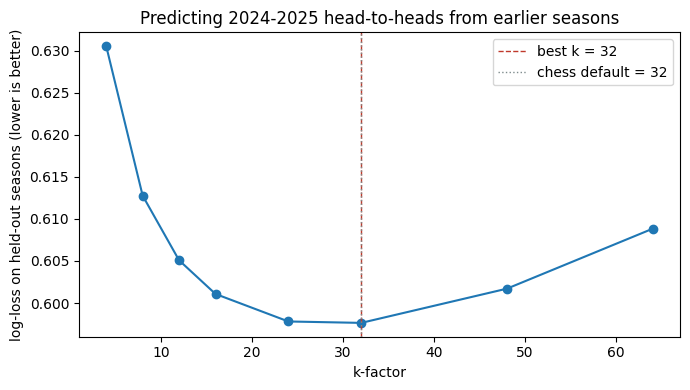

In [70]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_search.index, k_search['log_loss'], marker='o')
ax.axvline(best_k, color='#c0392b', ls='--', lw=1, label=f'best k = {best_k}')
ax.axvline(32, color='#7f8c8d', ls=':', lw=1, label="chess default = 32")
ax.set_xlabel('k-factor')
ax.set_ylabel('log-loss on held-out seasons (lower is better)')
ax.set_title('Predicting 2024-2025 head-to-heads from earlier seasons')
ax.legend()
plt.tight_layout()
plt.show()

### The chess default is not wrong, and the test cannot say more than that

**k = 32 gives the lowest log-loss, and 32 is the chess default.** But the gap to k = 24 is 0.0002,
and across k = 16 to 48 log-loss moves by only 0.004 on 389 held-out results against 0.033 over the
whole grid tested, so the curve is nearly flat where it matters and the test cannot separate the
candidates. 32 was tested rather than assumed, which is worth doing; it was not measured to be right.

**Accuracy and log-loss point at different values, and log-loss is the one to follow here.** Accuracy
is highest at k = 4, where ratings barely move from where they started, so nearly every prediction
comes out close to a coin flip. Being right 69% of the time while never committing to a view is worth
less than being right 67% of the time with confidence that is justified.

**The accuracy figure matters on its own: the higher-rated driver beats their teammate about two
thirds of the time.** So a teammate battle is predictable, but a long way from settled. Worth
holding on to before treating any single season's head-to-head record as proof of anything.

## Fitting the final ratings

With k settled at 32, the ratings are now fitted over every result from 2018 to 2025, with nothing
held back. The aim is no longer to forecast unseen races but to get the best estimate of each driver
from all the evidence available.

In [71]:
final_ratings, _ = run_elo(head_to_head, k=best_k)

appearances = pd.concat([head_to_head['winner'], head_to_head['loser']]).value_counts()

elo = pd.DataFrame({
    'elo': pd.Series(final_ratings),
    'head_to_heads': appearances,
})
elo['wins'] = head_to_head['winner'].value_counts().reindex(elo.index).fillna(0).astype(int)
elo['win_rate'] = elo['wins'] / elo['head_to_heads']

print(elo.sort_values('elo', ascending=False).round(3).to_string())

          elo  head_to_heads  wins  win_rate
VER  1898.974            147   131     0.891
SAI  1713.988            149    71     0.477
RUS  1709.278            135    99     0.733
LEC  1648.004            153   100     0.654
BOT  1614.585            125    67     0.536
ALB  1613.105            105    68     0.648
ALO  1601.054            119    84     0.706
GAS  1596.412            146    88     0.603
NOR  1591.287            136    87     0.640
HUL  1579.246             95    56     0.589
SIR  1560.082             15    11     0.733
BEA  1547.560             24    16     0.667
MSC  1544.881             41    25     0.610
PIA  1539.543             62    24     0.387
BOR  1537.200             23    11     0.478
GIO  1530.331             51    32     0.627
VET  1528.026             84    40     0.476
HAD  1515.164             23    15     0.652
DOO  1513.595              6     3     0.500
HAM  1508.473            149    74     0.497
GRO  1500.927             41    22     0.537
MAG  1485.

## Comparing against the hierarchical model

**Both methods now rank the same 43 drivers. Do the two orders match?**

They cannot be compared number against number, because they are measured on incompatible scales: Elo
points on one side, fractions of a second of lap time on the other. What can be compared is the
*order*. Spearman rank correlation does that. It throws away the values, keeps only the positions, and
scores +1 if the two rankings are identical, 0 if they are unrelated, and -1 if one is the reverse of
the other.

The comparison is run twice, because drivers with very few sessions are already known to be Elo's weak
point: once across all 43 drivers, and then again on only those with a long record of teammate duels.

In [72]:
posterior = idata.posterior
driver_draws = posterior['1|drv'].values.reshape(-1, posterior['1|drv'].shape[-1])
driver_names = posterior['1|drv'].coords['drv__factor_dim'].values

hierarchical = pd.Series(np.median(driver_draws, axis=0), index=driver_names, name='hierarchical')

both = elo.join(hierarchical)
# hierarchical: lower is faster. elo: higher is better. flip one so ranks align.
both['hier_rank'] = both['hierarchical'].rank()
both['elo_rank'] = (-both['elo']).rank()

full = spearmanr(both['hier_rank'], both['elo_rank'])
print(f'all {len(both)} drivers          : rho = {full.statistic:+.3f}  (p = {full.pvalue:.4f})')

for threshold in [20, 50, 100]:
    subset = both[both['head_to_heads'] >= threshold]
    result = spearmanr(subset['hier_rank'], subset['elo_rank'])
    print(f'{threshold:3d}+ head-to-heads ({len(subset):2d} drivers): '
          f'rho = {result.statistic:+.3f}  (p = {result.pvalue:.4f})')

all 43 drivers          : rho = +0.752  (p = 0.0000)
 20+ head-to-heads (32 drivers): rho = +0.812  (p = 0.0000)
 50+ head-to-heads (23 drivers): rho = +0.827  (p = 0.0000)
100+ head-to-heads (16 drivers): rho = +0.779  (p = 0.0004)


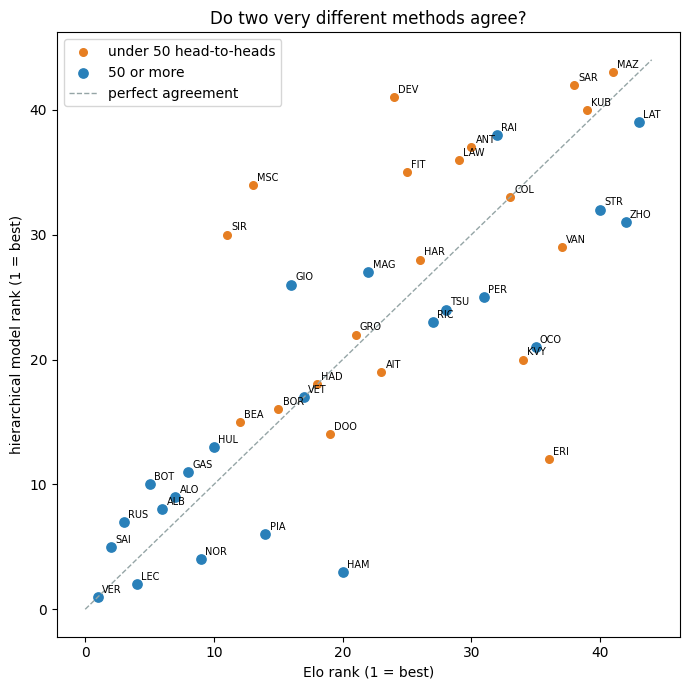

In [73]:
fig, ax = plt.subplots(figsize=(7, 7))
established = both['head_to_heads'] >= 50

ax.scatter(both.loc[~established, 'elo_rank'], both.loc[~established, 'hier_rank'],
           s=30, c='#e67e22', label='under 50 head-to-heads')
ax.scatter(both.loc[established, 'elo_rank'], both.loc[established, 'hier_rank'],
           s=45, c='#2980b9', label='50 or more')

for name, row in both.iterrows():
    ax.annotate(name, (row['elo_rank'], row['hier_rank']),
                fontsize=7, xytext=(3, 3), textcoords='offset points')

limit = len(both) + 1
ax.plot([0, limit], [0, limit], color='#95a5a6', ls='--', lw=1, label='perfect agreement')
ax.set_xlabel('Elo rank (1 = best)')
ax.set_ylabel('hierarchical model rank (1 = best)')
ax.set_title('Do two very different methods agree?')
ax.legend()
plt.tight_layout()
plt.show()

### The rankings hold up

| drivers included | ρ |
|---|---|
| all 43 | +0.752 |
| 20+ head-to-heads (32) | +0.812 |
| **50+ head-to-heads (23)** | **+0.827** |
| 100+ head-to-heads (16) | +0.779 |

**The two methods produce substantially the same order.**

**But +0.752 has no scale yet.** Two rankings built from nearly the same data were never going to be
uncorrelated, so testing against ρ = 0 tests nothing anyone believes. Nearly rather than exactly: the
model uses all 3,008 driver-sessions, while the duels need a teammate and so rest on the 2,950 that
had one. The question is what 0.75 is large or small compared with, and that needs two more numbers:
what a ranking with no model at all achieves, and what a better version of this same idea achieves.

The cell below computes three references. **Raw teammate win rate** ignores the opponent and the
order, and is the floor. **Bradley-Terry** is the model Elo approximates, fitted directly rather
than walked toward, so it is order-independent and converged. And **Elo run backwards** through the
calendar is the same method on the same duels, which separates what the data says from what the
ordering contributed.

In [74]:
from scipy.optimize import minimize


def agreement(rating):
    """Rank agreement with the hierarchical ranking. Higher rating means faster."""
    return spearmanr(both['hier_rank'], (-rating.reindex(both.index)).rank()).statistic


def bradley_terry(pairs, ridge=1e-3):
    """The model Elo approximates, fitted directly instead of walked toward.

    Order-independent and converged, so it separates what the duels say from what
    the sequential update happens to leave behind.
    """
    names = sorted(set(pairs['winner']) | set(pairs['loser']))
    position = {name: i for i, name in enumerate(names)}
    winner = pairs['winner'].map(position).to_numpy()
    loser = pairs['loser'].map(position).to_numpy()

    def negative_log_likelihood(strength):
        return (np.sum(np.logaddexp(0.0, -(strength[winner] - strength[loser])))
                + ridge * np.sum(strength ** 2))

    fitted = minimize(negative_log_likelihood, np.zeros(len(names)), method='L-BFGS-B')
    return pd.Series(fitted.x, index=names)


backwards_ratings, _ = run_elo(head_to_head.iloc[::-1].reset_index(drop=True), k=best_k)
backwards = pd.Series(backwards_ratings)
converged = bradley_terry(head_to_head)

print('rank agreement with the hierarchical ranking:')
for label, rating in [('teammate win rate, no model', both['win_rate']),
                      ('Elo', both['elo']),
                      ('Bradley-Terry, converged', converged)]:
    print(f'  {label:28s} {agreement(rating):+.3f}')

print()
print('agreement among the duel-based methods themselves:')
print(f'  Elo forwards vs Elo backwards '
      f'{spearmanr(both["elo"], backwards.reindex(both.index)).statistic:+.3f}')
print(f'  Elo vs Bradley-Terry          '
      f'{spearmanr(both["elo"], converged.reindex(both.index)).statistic:+.3f}')

shift = (backwards.reindex(both.index).rank(ascending=False) - both['elo_rank']).abs()
print()
print(f'running the same duels backwards moves a driver {shift.mean():.1f} places '
      f'on average, at most {int(shift.max())}')

both['backwards_rank'] = backwards.reindex(both.index).rank(ascending=False)
both['bt_rank'] = (-converged.reindex(both.index)).rank()

rank agreement with the hierarchical ranking:
  teammate win rate, no model  +0.646
  Elo                          +0.752
  Bradley-Terry, converged     +0.801

agreement among the duel-based methods themselves:
  Elo forwards vs Elo backwards +0.778
  Elo vs Bradley-Terry          +0.738

running the same duels backwards moves a driver 6.2 places on average, at most 21


In [75]:
both['rank_gap'] = both['hier_rank'] - both['elo_rank']

disagreements = both.reindex(both['rank_gap'].abs().sort_values(ascending=False).index)
print('largest disagreements (negative = Elo rates them lower than the model does):')
print(disagreements[['elo_rank', 'hier_rank', 'rank_gap',
                     'head_to_heads', 'win_rate']].head(10).round(2).to_string())
print()
print('what the other duel-based estimators say about those same drivers:')
print(disagreements[['hier_rank', 'elo_rank', 'backwards_rank', 'bt_rank']]
      .head(10).astype(int).to_string())

largest disagreements (negative = Elo rates them lower than the model does):
     elo_rank  hier_rank  rank_gap  head_to_heads  win_rate
ERI      36.0       12.0     -24.0             16      0.12
MSC      13.0       34.0      21.0             41      0.61
SIR      11.0       30.0      19.0             15      0.73
DEV      24.0       41.0      17.0             10      0.40
HAM      20.0        3.0     -17.0            149      0.50
KVY      34.0       20.0     -14.0             30      0.27
OCO      35.0       21.0     -14.0            133      0.43
ZHO      42.0       31.0     -11.0             59      0.31
GIO      16.0       26.0      10.0             51      0.63
FIT      25.0       35.0      10.0              2      0.00

what the other duel-based estimators say about those same drivers:
     hier_rank  elo_rank  backwards_rank  bt_rank
ERI         12        36              32       32
MSC         34        13               7       37
SIR         30        11              21     

### 0.75 is real, and Elo is noisier than the thing it is checking

Three references, all on the same 1,475 duels:

| ranking compared with the hierarchical model | ρ |
|---|---|
| teammate win rate, no model at all | +0.646 |
| Elo | +0.752 |
| **Bradley-Terry, converged** | **+0.801** |

**Elo's extra structure earns its place.** It beats the no-model floor by about a tenth, so the
calendar order and the opponent adjustment are doing real work rather than restating a win-rate table.

**And the better the second method, the more the two agree.** Bradley-Terry is Elo done properly, and
it lands at +0.801. That strengthens the check rather than weakening it: the closer the second method
gets to a converged estimate, the closer it gets to the hierarchical ranking.

**Which puts the disagreements in a different light.** Elo run backwards through the same duels agrees
with Elo run forwards at only **+0.778**, and moves a typical driver **6.2 places**, at most 21. So Elo
barely agrees with itself more than it agrees with a completely different model. Most of what looked
like two methods disagreeing is one method being unstable.

This cuts against the section that follows. Elo is a single pass with a fixed step size: it never
converges, and where a driver ends up depends on the order their duels arrived in.

## Where they disagree

Perfect agreement would have taught us nothing. The disagreements are the useful part, but each one
now has to survive three questions: does it hold when the calendar runs backwards, does it hold
under the converged fit, and is the record long enough to mean anything.

### Two kinds of disagreement, and only one survives

**Thin records account for four of the ten largest gaps**: Ericsson has 16 teammate duels here,
Sirotkin 15, de Vries 10, Fittipaldi 2. For those, neither method has much to work with, and the
hierarchical model is the one to believe because it says so.

Ericsson is the awkward case. He won 2 of his 16 duels, which puts him 36th on Elo, while the
hierarchical model leaves him 12th. Both the backwards run and the converged fit agree with Elo, not
with the model, so this is not an Elo artefact: it is a real disagreement about a driver whose entire
record is 16 laps against one teammate.

**The other six are long records, and this is where the instability shows.** Mick Schumacher has 41
duels and sits 13th on Elo against 34th in the model, the second largest gap in the table. His record
is two halves: **19 duels against Mazepin in 2021, all 19 won**, then 22 against Magnussen in 2022 of
which he won 6. Elo banks the perfect run first and the fixed step size never fully gives it back. Run
the calendar backwards and he rises to 7th; fit Bradley-Terry, which weighs all 41 duels at once
instead of walking through them, and he falls to 37th, next to the hierarchical model's 34th. His Elo
is not a finding about Schumacher, it is a record of which half of his career arrived first.

Ocon goes the same way: 35th on Elo, 19th backwards, 15th converged, against 21st in the model. **The
apparent disagreement dissolves.**

**Hamilton is the one that does not.** 149 duels, 3rd in the model, 20th on Elo, and 18th under the
converged fit, which has no path dependence at all. Running the calendar backwards lifts him to 9th,
so some of the gap is order, but not most of it. Something about the teammate comparison rates him
lower than the absolute measure does, and that needs an explanation.

In [76]:
def teammate_record(driver):
    faced = head_to_head[(head_to_head['winner'] == driver) | (head_to_head['loser'] == driver)]
    opponent = np.where(faced['winner'] == driver, faced['loser'], faced['winner'])
    won = faced['winner'] == driver
    record = (pd.DataFrame({'teammate': opponent, 'won': won})
              .groupby('teammate')['won'].agg(['sum', 'count']))
    record.columns = ['wins', 'races']
    record['win_rate'] = (record['wins'] / record['races']).round(3)
    record['teammate_elo'] = elo['elo'].reindex(record.index).round(0)
    return record.sort_values('races', ascending=False)


for driver in ['HAM', 'OCO']:
    print(f'--- {driver} (Elo {elo.loc[driver, "elo"]:.0f}, '
          f'rank {int(both.loc[driver, "elo_rank"])} vs model rank '
          f'{int(both.loc[driver, "hier_rank"])}) ---')
    print(teammate_record(driver).to_string())
    print()

--- HAM (Elo 1508, rank 20 vs model rank 3) ---
          wins  races  win_rate  teammate_elo
teammate                                     
BOT         40     65     0.615        1615.0
RUS         26     60     0.433        1709.0
LEC          8     24     0.333        1648.0

--- OCO (Elo 1393, rank 35 vs model rank 21) ---
          wins  races  win_rate  teammate_elo
teammate                                     
ALO         18     43     0.419        1601.0
GAS         18     37     0.486        1596.0
BEA          7     23     0.304        1548.0
RIC          7     16     0.438        1462.0
PER          7     14     0.500        1445.0



### Hamilton never had a weak teammate

| Hamilton's teammates | races | win rate | their Elo |
|---|---|---|---|
| Bottas | 65 | 61.5% | 1615 |
| Russell | 60 | 43.3% | 1709 |
| Leclerc | 24 | 33.3% | 1648 |

**Those are three of the strongest drivers in the dataset, and Hamilton faced nobody else.** A
teammate-based rating can only measure you against the driver your team happened to put in the other
car, and his were as hard a set as anyone got.

**A rating rises fastest against a weak opponent held over many races**, not because any single win
counts for much, but because the gap compounds every time. Russell built part of his rating against
Latifi, who won 7 of his 59 duels across all his teammates. Verstappen won 89% of his.

Two things stop this being the whole story.

**The mechanism does not fit everyone it should.** Sainz sits 2nd on Elo with a 47.7% win rate, a
*losing* record against a teammate set as strong as Hamilton's: Hülkenberg, Norris, Leclerc, Albon.
If facing strong teammates were enough to sink a rating, Sainz could not be second. The converged fit
moves him to 5th and running the calendar backwards moves him to 11th, so a good part of his position
is the same instability that produced Schumacher's.

**And Ocon is not the same case.** An earlier version of this section grouped him with Hamilton
because both have long records and both rate low on Elo. But two of his five teammates, Ricciardo and
Pérez, sit below the 1500 starting rating on this notebook's own numbers, and he beat neither:
7 wins in 16 against Ricciardo and 7 in 14 against Perez, a losing record and an even one. His low Elo
is not a strong-teammate problem, and the converged fit lifts him 20 places.

**What survives is narrower than it first looked, and still worth having.** Hamilton is low on every
duel-based estimator and high on the absolute one. Whether that is a limitation of teammate-based
rating or a real disagreement about Hamilton, this notebook cannot settle. What it can say is that a
teammate comparison measures something that depends on your teammate, and an absolute measure does
not.

### Which is right?

**Neither, exactly. They answer different questions, and both answers are true.**

- **Elo asks: did you beat the driver in the identical car?** A fair fight, but how hard that fight was
  depends on who that driver happened to be, and the answer moves by six places if the calendar runs
  backwards.
- **The hierarchical model asks: how fast were you in absolute terms, once the car has been accounted
  for?** That does not depend on who your team hired, but it does rely on separating driver from car
  correctly, and notebook 03 showed that separation is imperfect where teams deliberately run below
  their true pace in Q1.

For ranking driver skill I would trust the absolute measure more. But that is a judgement, and it holds
only if the adjustment for the car is right.

This also gives a second reason for a decision taken back in notebook 01. The gap to your teammate was
rejected as the thing to model because subtracting one teammate's time from the other's cancels the car
out, which leaves constructor strength impossible to estimate. There is a second problem with it:
**it measures something that depends on your teammate, not only on you.**

## Quantified takeaways

1. **The ranking survives being rebuilt by a different method, and the check now has a scale.** Elo
   agrees with the hierarchical ranking at ρ = +0.752, against +0.646 for a raw win-rate table with no
   model at all and +0.801 for a converged Bradley-Terry fit. The order is in the data rather than in
   the hierarchical model's assumptions, and the better the second method, the closer the agreement.

2. **The second method is noisier than the thing it checks.** Running the same duels backwards moves a
   driver 6.2 places on average and agrees with the forward run at only +0.778, barely more than Elo's
   agreement with a completely different model. Elo is one pass with a fixed step size and never
   converges, so any single rating is partly an accident of ordering.

3. **The higher-rated driver beats their teammate about two thirds of the time** (67% on the held-back
   seasons). Teammate battles are predictable but far from settled, which is worth remembering before
   reading one season's head-to-head record as proof of anything.

4. **k was tested rather than assumed, and the test could not separate much.** Log-loss is lowest at
   k = 32, the chess default, but the curve is flat from 16 to 48, moving 0.004 across that span on
   389 held-out results, against 0.033 over the whole grid. The choice does not matter over a wide
   range; 32 was not measured to be right.

5. **Two of the three headline disagreements dissolve under a converged fit.** Mick Schumacher moves
   from 13th on Elo to 37th and Ocon from 35th to 15th, both landing near the hierarchical model's
   answer. Hamilton is the one that survives: 3rd in the model, 20th on Elo, 18th converged, across a
   full 149-duel record. A teammate comparison measures something that depends on who was in the other
   car, which is a second reason, beyond cancelling out the constructor effect, not to have modelled
   the gap to your teammate.